### What exactly is object detection?

What exactly is object detection?

Before discussing YOLO or R-CNN, we need to establish what problem object detection solves.

Consider an image containing:

- Two people
- One car
- One bicycle

There are three different computer vision tasks we can perform.

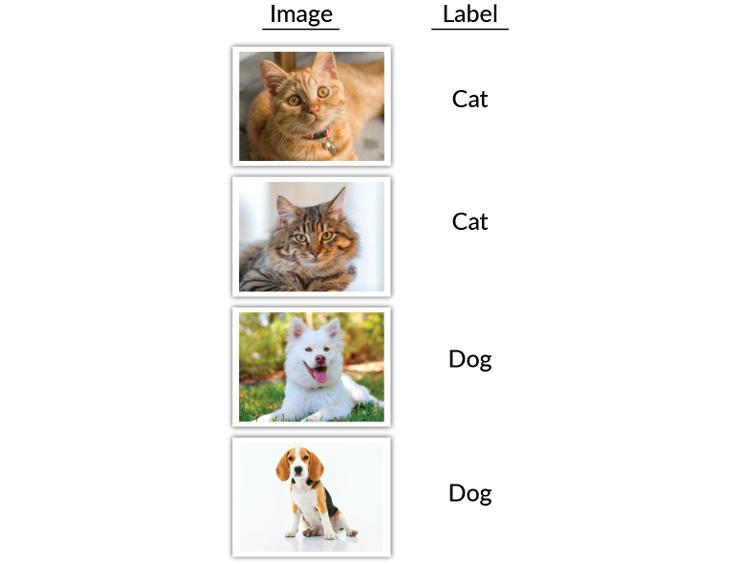

Image classification

What objects are present in the image?

Object detection

What objects are present, and where are they?

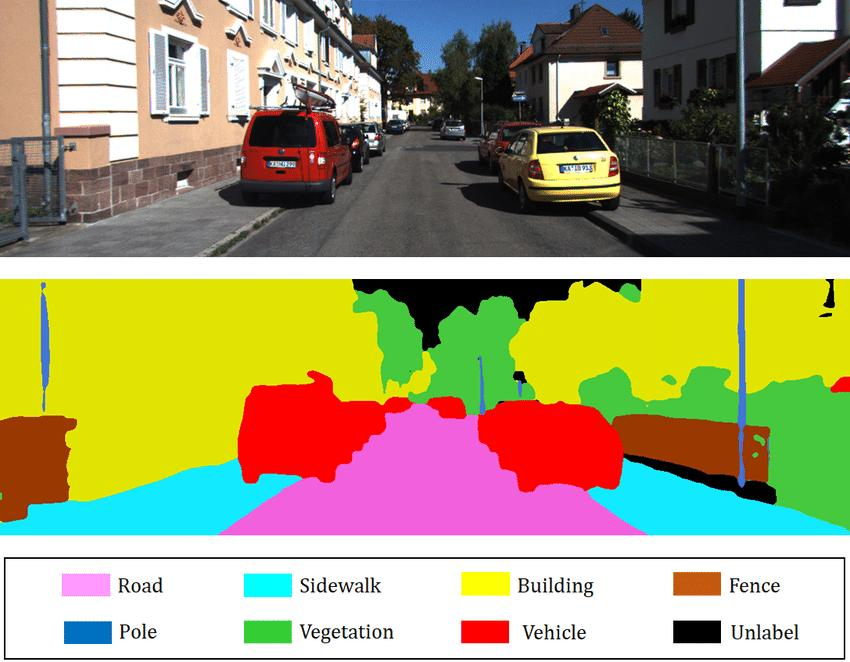!
Semantic segmentation

Which class does each pixel belong to?

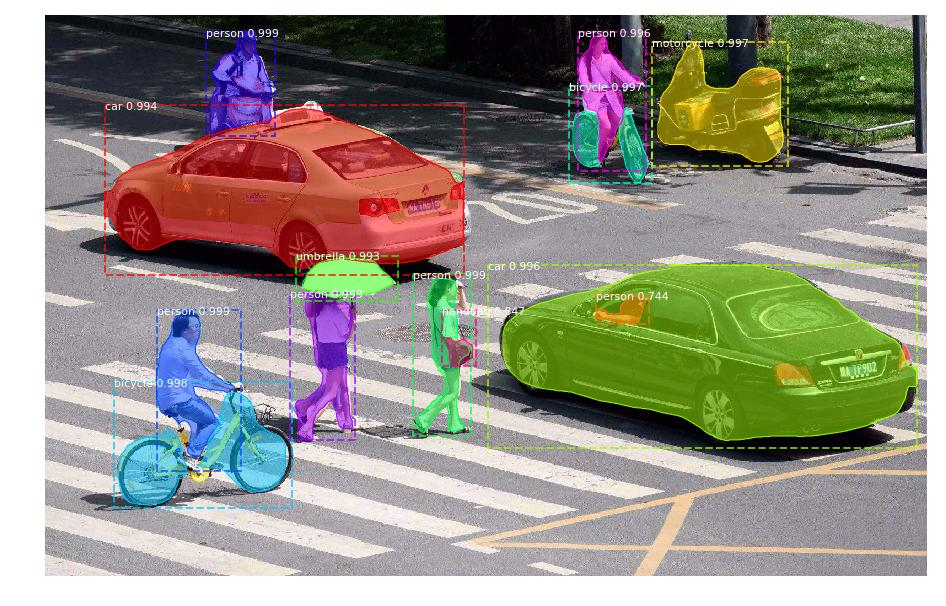!

Instance segmentation

Which pixels belong to each individual object?

### The key difference

| Task                  | Output                      |
| --------------------- | --------------------------- |
| Classification        | Class label                 |
| Object detection      | Class label + bounding box  |
| Semantic segmentation | Class label for every pixel |
| Instance segmentation | Individual object masks     |

### How does object detection represent an object?

Instead of predicting only a class such as `car`, the model also predicts a rectangular region around that car.

A bounding box can be represented using four values:

\\[ (x\_{\min},y\_{\min},x\_{\max},y\_{\max}) \\]

Alternatively, some models use:

\\[ (x_c,y_c,w,h) \\]

Where:

- \\(x_c,y_c\\): centre of the bounding box
- \\(w,h\\): width and height

These coordinates may be normalized relative to image width and height, depending on the model and dataset.

Important conceptual shift: A classification CNN answers what is in this image? An object detector answers what is in this image, and where is each object?

# Topic 2: How Does an Object Detection Model Predict Bounding Boxes?

In image classification, the model predicts what an image contains. For example, given an image, it might predict that the image contains a dog.

But object detection needs to answer two questions:

1. What is the object?
2. Where exactly is the object located?

Let's understand how a model learns to predict the location of an object.

## 1. Understanding the problem through an example

Imagine we give the following image to an object detection model.

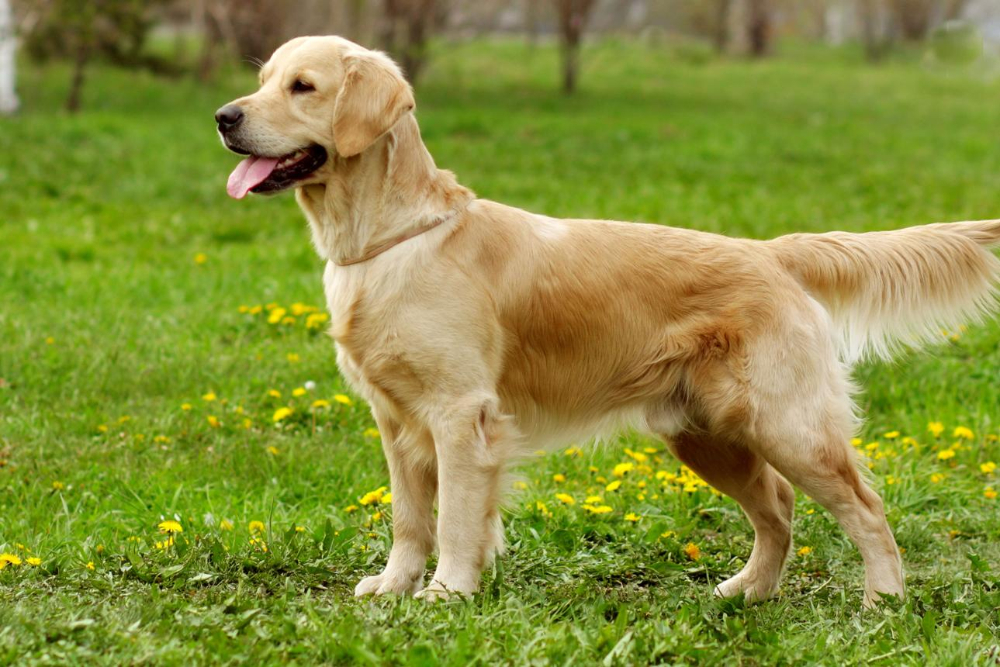!

The model needs to identify the dog and draw a rectangular box around it.

This rectangle is called a bounding box.

But how do we represent the location of this rectangle mathematically?

There are two common representations.

Representation 1: Corner coordinates

We specify the top-left and bottom-right corners:

\\[ (x\_{\min},y\_{\min},x\_{\max},y\_{\max}) \\]

Representation 2: Centre coordinates and dimensions

We specify:

\\[ (x_c,y_c,w,h) \\]

Where:

- \\(x_c\\): X-coordinate of the rectangle's centre.
- \\(y_c\\): Y-coordinate of the rectangle's centre.
- \\(w\\): Width of the rectangle.
- \\(h\\): Height of the rectangle.

Let's understand the second representation in detail, because it is commonly used in YOLO-style object detection.

## 2. Why do we represent a bounding box using its centre?

Consider a rectangular box drawn somewhere inside an image.

Illustrative bounding box. The rectangle can be anywhere within the image.

Why use the centre?

Because we can describe the entire rectangle using just four values:

- Where its centre is located.
- How wide it is.
- How tall it is.

Notice that the centre is the centre of the object's bounding box, not necessarily the centre of the image.

The object could be towards the left, right, top or bottom. Its centre coordinates simply change accordingly.

For example:

| Object location | Normalized centre coordinates |
| --------------- | ----------------------------- |
| Top-left        | (0.2, 0.2)                    |
| Centre          | (0.5, 0.5)                    |
| Bottom-right    | (0.8, 0.8)                    |

The model learns these locations from annotated training images. It does not assume that objects are located at the centre.

## 3. Understanding normalized coordinates

Let's assume our input image has dimensions:

\\[ 640\times640 \\]

Instead of predicting pixel coordinates directly, many detection models use normalized coordinates between 0 and 1.

Why?

Because the same object location can be represented independently of the actual image resolution.

For example:

- An object centre at 320 pixels in a 640-pixel-wide image corresponds to 0.5.
- An object centre at 160 pixels in a 320-pixel-wide image also corresponds to 0.5.

The relative position is the same.

The normalization is:

\\[ x_c=\frac{\text{Centre X in pixels}}{\text{Image width}} \\]

\\[ y_c=\frac{\text{Centre Y in pixels}}{\text{Image height}} \\]

Similarly:

\\[ w=\frac{\text{Box width in pixels}}{\text{Image width}} \\]

\\[ h=\frac{\text{Box height in pixels}}{\text{Image height}} \\]

Suppose our model predicts:

\\[ [x_c,y_c,w,h]=[0.5,0.6,0.4,0.3] \\]

Let's convert these values into pixels.

| Parameter | Calculation | Result |
| --------- | ----------- | ------ |
| Centre X  | 0.5 × 640   | 320    |
| Centre Y  | 0.6 × 640   | 384    |
| Width     | 0.4 × 640   | 256    |
| Height    | 0.3 × 640   | 192    |

So the centre of the predicted bounding box is at pixel location (320, 384), with a width of 256 pixels and a height of 192 pixels.

## 4. How do we calculate the four corners?

We now know the centre, width and height.

But suppose we want the top-left and bottom-right coordinates. How do we calculate them?

Think about a rectangle.

If its centre is at X = 320 and its total width is 256, the centre divides the width into two equal halves.

\\[ \text{Half width}=\frac{256}{2}=128 \\]

Therefore:

- Left boundary = Centre X − Half width
- Right boundary = Centre X + Half width

Mathematically:

\\[ x\_{\min}=x_c-\frac{w}{2} \\]

\\[ x\_{\max}=x_c+\frac{w}{2} \\]

Similarly, for the vertical direction:

\\[ \text{Half height}=\frac{192}{2}=96 \\]

The image coordinate system starts at the top-left corner. X increases towards the right, and Y increases downwards.

Therefore:

- Top boundary = Centre Y − Half height
- Bottom boundary = Centre Y + Half height

\\[ y\_{\min}=y_c-\frac{h}{2} \\]

\\[ y\_{\max}=y_c+\frac{h}{2} \\]

Let's substitute our values.

| Coordinate      | Calculation | Result |
| --------------- | ----------- | ------ |
| \\(x\_{\min}\\) | 320 − 128   | 192    |
| \\(y\_{\min}\\) | 384 − 96    | 288    |
| \\(x\_{\max}\\) | 320 + 128   | 448    |
| \\(y\_{\max}\\) | 384 + 96    | 480    |

Our final bounding box is:

\\[ (192,\ 288,\ 448,\ 480) \\]

This is the same rectangle, simply represented using corner coordinates instead of centre coordinates.

## 5. But how does the model learn to predict these coordinates?

This is where we connect object detection to the CNN and backpropagation concepts.

During training, we provide the model with:

- An image.
- Its corresponding ground-truth bounding boxes.
- The correct class labels.

For example, suppose the ground-truth annotation for a dog is:

\\[ [500,\ 400,\ 100,\ 150] \\]

Here, the annotation represents:

- Centre X = 500
- Centre Y = 400
- Width = 100
- Height = 150

Initially, the model may predict:

\\[ [300,\ 300,\ 80,\ 100] \\]

The predicted box does not match the ground-truth box.

The model calculates a loss based on the difference between its prediction and the actual annotation.

Then:

1. Forward propagation generates bounding box and class predictions.
2. The loss function measures prediction errors.
3. Backpropagation calculates gradients.
4. The optimizer updates the network weights.
5. This process repeats over many training examples.

Gradually, the model learns visual patterns that help it predict object locations and dimensions.

Important: The ground-truth bounding boxes are supplied during training. The model learns to predict them; it is not given the correct coordinates when making predictions on a new image.

## 6. Objectness and class predictions

Predicting the bounding box alone is not sufficient. The model must also identify what is inside it.

A classic YOLO-style prediction can be represented as:

\\[ [x_c,y_c,w,h,o,p_1,p_2,\ldots,p_C] \\]

Where:

- \\(x_c,y_c,w,h\\): Bounding box coordinates.
- \\(o\\): Objectness score.
- \\(p_1,p_2,\ldots,p_C\\): Class scores.

For example:

| Prediction | Value |
| ---------- | ----- |
| Objectness | 0.95  |
| Dog score  | 0.90  |
| Cat score  | 0.05  |
| Car score  | 0.02  |

Objectness estimates whether the predicted region contains an object.

Class scores indicate which object category is predicted.

In the classic YOLO formulation, the final confidence for the dog class is:

\\[ 0.95\times0.90=0.855 \\]

Therefore, the final dog confidence is 85.5%.

Architecture note: This is the classic YOLO-style formulation. Modern YOLO architectures, such as YOLOv8, use a different prediction-head design and do not have a separate objectness output in the same way.

## 7. Understanding the different loss components

Object detection involves multiple prediction tasks, so the training objective generally combines multiple losses.

\\[ L\_{\text{total}}= L\_{\text{box}}+ L\_{\text{classification}}+ L\_{\text{objectness}} \\]

| Loss component      | What does it measure?                                            |
| ------------------- | ---------------------------------------------------------------- |
| Box loss            | How accurately does the predicted box match the actual box?      |
| Classification loss | How accurately does the model identify the object category?      |
| Objectness loss     | How accurately does the model identify whether an object exists? |

The exact loss functions vary across architectures. For example, modern detectors often use IoU-based bounding box losses.

## 8. What have we understood so far?

We have established that object detection requires the model to predict:

1. The location of an object.
2. Its width and height.
3. Its class.
4. Its confidence.

But there is one important question we haven't answered yet:

How does the model know where to look in the image?

Does it predict one bounding box for the entire image? Does it divide the image into regions? Can it predict multiple objects?

This brings us to the next concept: Grid-based object detection and how YOLO divides an image into cells to detect multiple objects.

We'll use this to understand the original YOLO approach before moving into anchors, modern YOLO prediction heads and Non-Maximum Suppression.

# Topic 3: Grid-Based Object Detection – How Does YOLO Locate Objects?

In the previous topic, we understood that an object detection model predicts:

- The object's location (bounding box).
- Its dimensions (width and height).
- Its class.
- Its confidence.

But one question remains:

How does the model search the entire image and decide where to predict bounding boxes?

Let's understand this through the original YOLO approach.

## 1. Why divide an image into a grid?

Imagine giving a 640 × 640 image to an object detection model.

The image may contain several objects, and they could appear anywhere.

One approach is to divide the image into smaller regions so that the model can make predictions across the entire image.

For example, let's divide the image into an 8 × 8 grid.

A 640 × 640 image divided into an 8 × 8 grid

Illustrative grid. Each cell is 80 × 80 pixels.

Since the image is 640 × 640 and we have 8 rows and 8 columns:

\\[ \text{Cell width}=\frac{640}{8}=80 \\]

\\[ \text{Cell height}=\frac{640}{8}=80 \\]

So each cell represents an 80 × 80 pixel region.

The idea is that different regions of the image participate in predicting objects at different locations.

## 2. Which grid cell is responsible for detecting an object?

This is the most important concept.

In the original YOLO formulation, the grid cell containing the centre of an object's ground-truth bounding box is responsible for predicting that object.

Let's understand this.

Suppose the centre of a dog is located at:

\\[ (x_c,y_c)=(197.5,160) \\]

Remember, our cell size is 80 × 80.

We can calculate the grid position:

\\[ \text{Column}=\left\lfloor\frac{197.5}{80}\right\rfloor=2 \\]

\\[ \text{Row}=\left\lfloor\frac{160}{80}\right\rfloor=2 \\]

Therefore, the cell at row 2, column 2 (using zero-based indexing) is responsible for predicting this dog.

Notice something interesting:

The dog itself may occupy several grid cells. But the cell containing its centre is responsible for predicting it.

The grid cell is not predicting only the part of the object inside that cell. It predicts the bounding box of the entire object.

This is a crucial distinction.

## 3. What does each grid cell actually predict?

In the original YOLO (YOLOv1), each grid cell predicts:

1. B bounding boxes.
2. A confidence score for each bounding box.
3. Class probabilities for the cell.

For example, YOLOv1 used:

- A 7 × 7 grid.
- 2 bounding boxes per grid cell.
- 20 object classes (in the PASCAL VOC setup).

Its output was:

\\[ 7\times7\times(2\times5+20) \\]

\\[ =7\times7\times30 \\]

Each bounding box has five values:

\\[ (x,y,w,h,\text{confidence}) \\]

The 20 class probabilities are predicted per grid cell.

This gives an output tensor of:

\\[ 7\times7\times30 \\]

Don't worry about memorising this. The important takeaway is that the model produces predictions across the grid, rather than predicting just one box for the entire image.

## 4. What happens when there are multiple objects?

Imagine an image containing three objects:

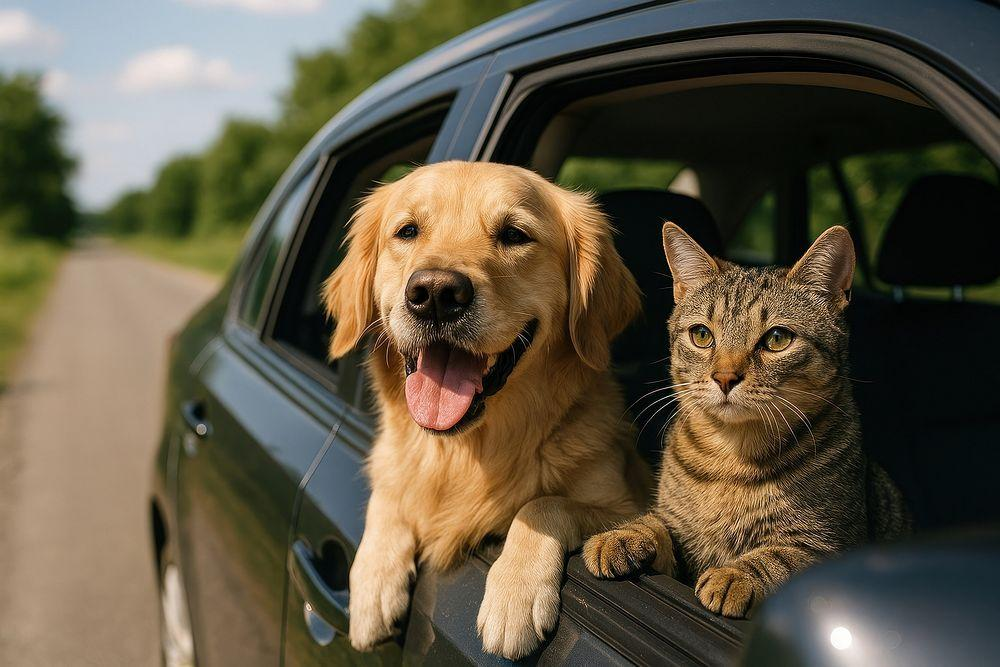!

Each object's centre may fall into a different grid cell.

The corresponding cells become responsible for predicting those objects.

However, the original YOLOv1 approach has a limitation.

What if two objects have their centres in the same grid cell?

YOLOv1 assigns responsibility based on the object's centre, and its cell-level class prediction makes it difficult to handle multiple objects of different classes whose centres fall in the same cell.

This is one of the limitations addressed by later detection architectures.

## 5. Important: Is this how every modern YOLO works?

Not exactly.

The grid-based explanation is particularly useful for understanding the original YOLO architecture.

Modern YOLO versions have evolved:

- Different prediction scales are used to detect objects of different sizes.
- Anchor-based versions use predefined box shapes as starting references.
- Anchor-free versions predict object locations and box dimensions without predefined anchor boxes.
- Modern prediction heads and assignment strategies differ from YOLOv1.

# Topic 4: IoU – Intersection over Union

Suppose the actual dog bounding box is drawn in green, and our model predicts a bounding box in red.

How do we measure whether the model has drawn the box accurately?

We use IoU (Intersection over Union).

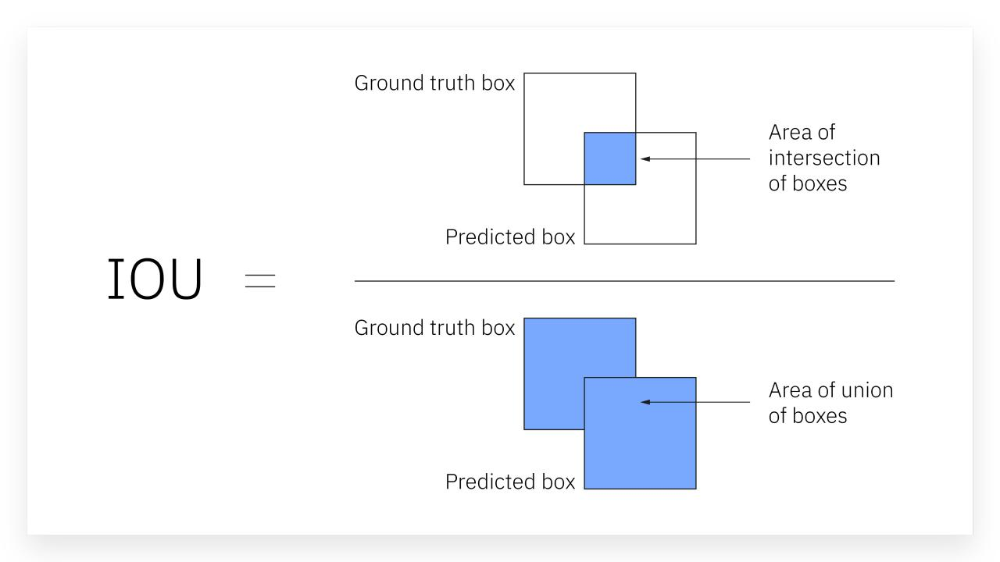

IoU measures how much the predicted box overlaps with the actual box.

\\[ IoU=\frac{\text{Area of Intersection}}{\text{Area of Union}} \\]

- Intersection: The common area shared by both boxes.
- Union: The total area covered by both boxes together, without counting overlapping area twice.

## Numerical example

Suppose:

- Actual bounding box area = 100
- Predicted bounding box area = 100
- Overlapping area = 60

Union area:

\\[ 100+100-60=140 \\]

Therefore:

\\[ IoU=\frac{60}{140}=0.4286 \\]

IoU = 0.43

This means the predicted box has approximately 43% overlap relative to the combined area.

## How do we interpret IoU?

| IoU  | Interpretation   |
| ---- | ---------------- |
| 0    | No overlap       |
| 0.25 | Low overlap      |
| 0.50 | Moderate overlap |
| 0.75 | Good overlap     |
| 1.00 | Perfect overlap  |

Why is IoU important?

During object detection evaluation, we need a criterion to decide whether a predicted bounding box is sufficiently close to the ground-truth box.

For example, an IoU threshold of 0.5 means a prediction needs at least 50% overlap to qualify as a correct localization, subject to the correct class and other evaluation rules.

Remember: IoU measures bounding-box overlap, not whether the predicted class is correct.


# Topic 5: Non-Maximum Suppression (NMS)

Imagine an image contains one dog. The object detection model identifies the dog but produces five overlapping bounding boxes around it.

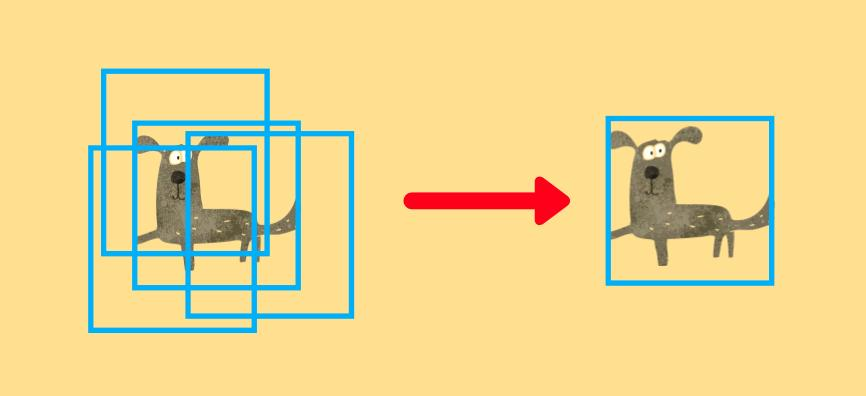!

Which box should we retain? We don't want to report the same dog five times!

This is where Non-Maximum Suppression (NMS) comes in.

## How does NMS work?

NMS follows a simple process:

1. Identify all predicted bounding boxes.
2. Look at their confidence scores.
3. Select the box with the highest confidence.
4. Calculate IoU between this selected box and the remaining boxes.
5. Remove boxes that overlap too much with the selected box (above a chosen IoU threshold).
6. Repeat until the remaining boxes have been processed.

## Numerical example

Suppose the model predicts four boxes for the same dog:

| Bounding box | Confidence |
| ------------ | ---------- |
| Box A        | 0.95       |
| Box B        | 0.90       |
| Box C        | 0.75       |
| Box D        | 0.60       |

Assume our NMS IoU threshold is 0.5.

We select Box A because it has the highest confidence.

Now compare the other boxes against Box A:

| Comparison | IoU  | Decision |
| ---------- | ---- | -------- |
| A vs B     | 0.85 | Remove B |
| A vs C     | 0.70 | Remove C |
| A vs D     | 0.20 | Keep D   |

Why?

- B and C overlap heavily with A, so they are likely duplicate detections.
- D has relatively little overlap, so it may represent another object.

The final detections are A and D.

## NMS in one glance

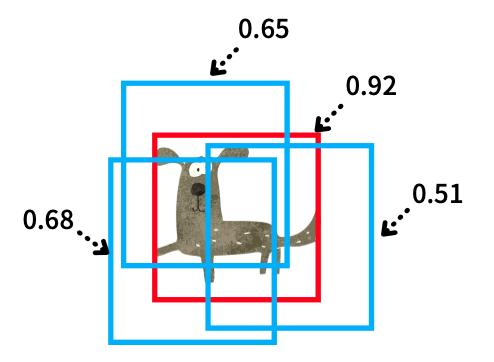!

Before NMS

Multiple overlapping predictions

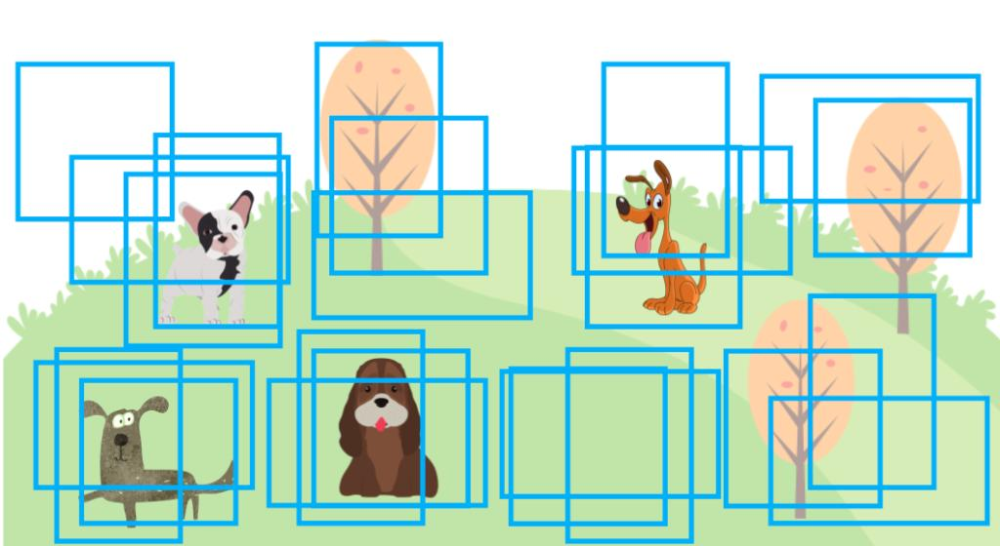!
After NMS

Duplicate boxes suppressed

## One important distinction

- IoU measures how much two bounding boxes overlap.
- NMS uses IoU and confidence scores to remove duplicate detections.

NMS is generally applied separately for each class in class-wise NMS. This prevents a dog box from suppressing an overlapping cat box merely because they overlap.

Remember: NMS does not improve the model's predictions. It filters redundant predictions to produce cleaner detection results.

### Quick recap

We've now covered three important concepts:

| Concept        | Purpose                     |
| -------------- | --------------------------- |
| Bounding boxes | Locate objects              |
| IoU            | Measure box overlap         |
| NMS            | Remove duplicate detections |


# Topic 6: Evaluating Object Detection – Precision, Recall, AP and mAP

We've understood how an object detection model predicts bounding boxes, measures overlap using IoU and removes duplicate predictions using NMS.

Now the question is: How do we evaluate whether an object detection model is performing well?

Let's understand this using a simple example.

## 1. True Positive, False Positive and False Negative

Suppose an image contains 5 actual dogs.

Our model detects 4 dogs, but one of its detections is incorrect.

| Metric              | Count | Meaning                 |
| ------------------- | ----- | ----------------------- |
| True Positive (TP)  | 3     | Correctly detected dogs |
| False Positive (FP) | 1     | Incorrect detection     |
| False Negative (FN) | 2     | Dogs the model missed   |

For this example, assume a detection counts as correct only when its class is correct and its IoU meets the chosen threshold.

## 2. Precision – How many predictions were correct?

Precision answers:

Out of all the objects detected by the model, how many were actually correct?

\\[ Precision=\frac{TP}{TP+FP} \\]

Substituting:

\\[ Precision=\frac{3}{3+1}=0.75 \\]

Precision = 75%

The model made 4 detections, of which 3 were correct.

Higher precision means fewer false detections.

## 3. Recall – How many actual objects did we find?

Recall answers:

Out of all the objects actually present, how many did the model successfully detect?

\\[ Recall=\frac{TP}{TP+FN} \\]

Substituting:

\\[ Recall=\frac{3}{3+2}=0.60 \\]

Recall = 60%

There were 5 actual dogs, and the model detected 3 correctly.

Higher recall means fewer missed objects.

## 4. Precision vs Recall – What's the difference?

Imagine building an object detector for surveillance.

- If we want to avoid raising alerts for objects that aren't actually threats, precision becomes important.
- If we want to ensure that we don't miss any potential threats, recall becomes important.

| Metric    | Focus                        |
| --------- | ---------------------------- |
| Precision | Avoid false detections       |
| Recall    | Avoid missing actual objects |

There is often a trade-off between precision and recall. Changing the confidence threshold can affect both.

## 5. What are AP and mAP?

Now let's move to the metrics commonly used in object detection.

Average Precision (AP) measures detection performance for one object class across different confidence thresholds.

Rather than calculating precision at just one threshold, we examine the Precision-Recall curve and calculate the area under it (using a specified interpolation/integration method).

For example:

- Dog AP = 0.90
- Cat AP = 0.85
- Car AP = 0.95

Mean Average Precision (mAP) calculates the mean of AP across all object classes.

\\[ mAP=\frac{\sum AP\_{\text{classes}}}{N} \\]

For our example:

\\[ mAP=\frac{0.90+0.85+0.95}{3} \\]

\\[ mAP=0.90 \\]

mAP = 90%

The model's average precision across the three classes is 90%.

## 6. What is mAP\@50 and mAP\@50:95?

You'll frequently encounter these terms when working with YOLO and other object detection frameworks.

| Metric     | Meaning                                                                     |
| ---------- | --------------------------------------------------------------------------- |
| mAP\@50    | Evaluates detections using IoU threshold 0.50                               |
| mAP\@75    | Evaluates detections using IoU threshold 0.75                               |
| mAP\@50:95 | Averages mAP across IoU thresholds from 0.50 to 0.95, in increments of 0.05 |

For example, mAP\@50:95 evaluates localization at progressively stricter overlap requirements.

A model might have a high mAP\@50 but a lower mAP\@50:95 because its boxes are not consistently precise.

## Quick recap

| Metric     | What does it tell us?                                              |
| ---------- | ------------------------------------------------------------------ |
| Precision  | How many predicted detections were correct?                        |
| Recall     | How many actual objects were detected?                             |
| AP         | How well does the model detect one particular class?               |
| mAP        | How well does the model perform across all classes?                |
| mAP\@50:95 | How well does it perform across different localization thresholds? |


R-CNN, Fast R-CNN and Faster R-CNN

All three belong to the region-based object detection family.

Imagine an image containing a dog, a car and a person. Rather than predicting everything directly, the R-CNN family works with candidate regions—parts of the image that might contain objects.

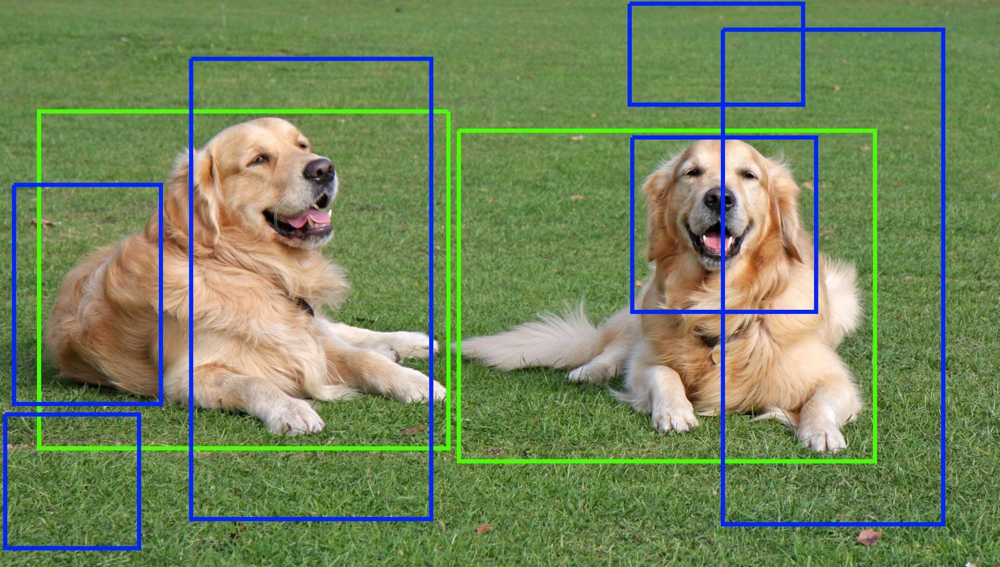!

1\. R-CNN (2014)

Finds candidate regions using Selective Search, crops each region and runs a CNN separately to extract features. It then classifies the regions and refines their bounding boxes.

Problem: Very slow because the CNN processes thousands of regions separately.

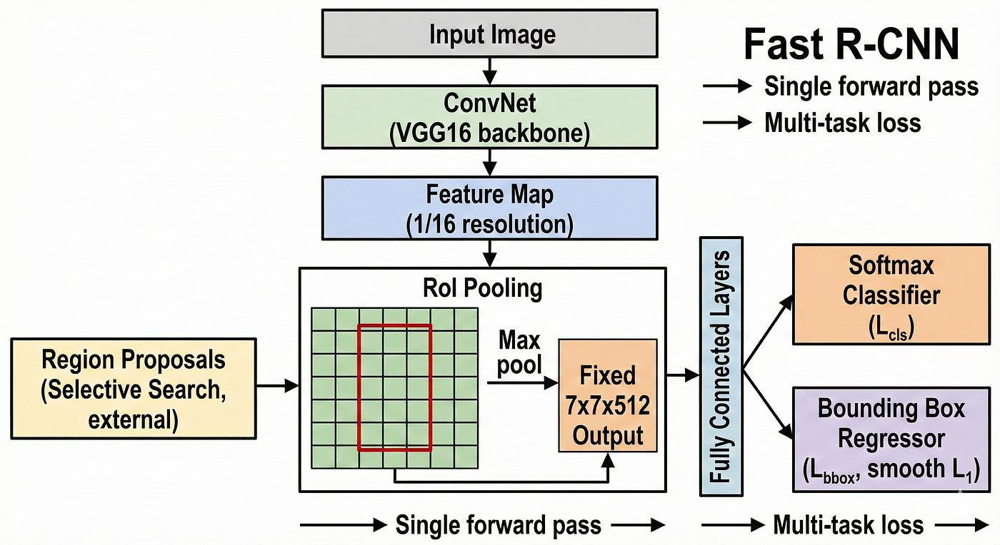!

2\. Fast R-CNN (2015)

Runs the CNN on the image only once to generate a shared feature map. Candidate regions are mapped onto that feature map, and RoI pooling extracts features for classification and bounding-box refinement.

Improvement: Much faster, but Selective Search is still an external bottleneck.

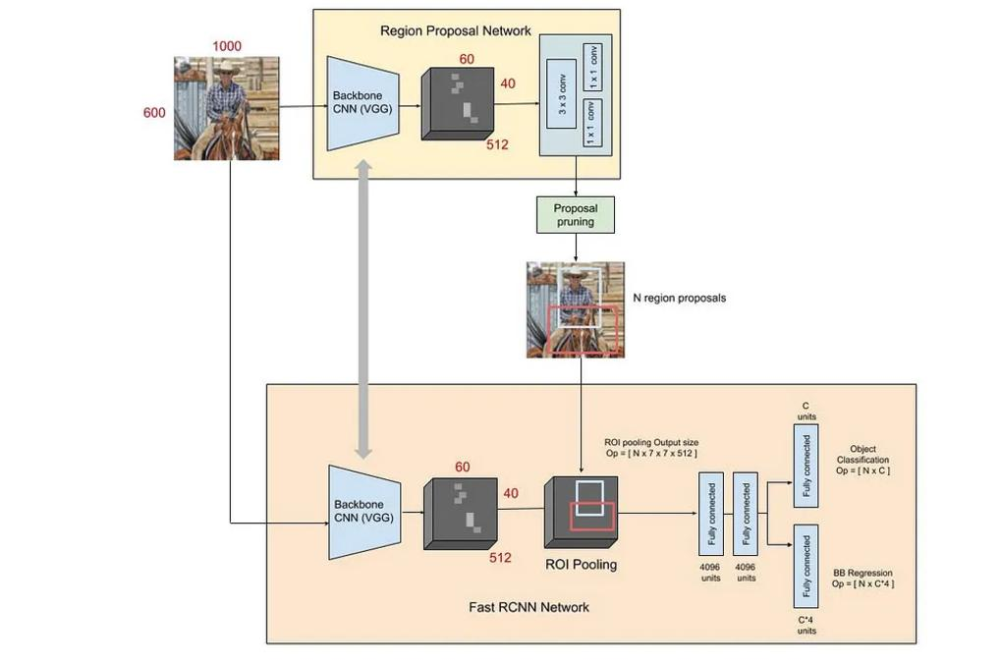!
3\. Faster R-CNN (2015)

Replaces Selective Search with a Region Proposal Network (RPN), which learns to propose candidate object regions directly from CNN features.

Improvement: Region proposals become part of the trainable neural-network pipeline.

### The difference in one table

| Architecture | How regions are proposed | Main idea                                         |
| ------------ | ------------------------ | ------------------------------------------------- |
| R-CNN        | Selective Search         | CNN runs separately for each region               |
| Fast R-CNN   | Selective Search         | CNN features are shared                           |
| Faster R-CNN | Region Proposal Network  | CNN features and learned proposals are integrated |

### What is a two-stage detector?

Faster R-CNN is called a two-stage detector because it performs two major operations:

Input image → CNN feature maps

Stage 1: Region Proposal Network

Where might objects be located?

Stage 2: Detection Head

What is each object, and what is its refined bounding box?

### What should we remember?

R-CNN → Fast R-CNN → Faster R-CNN represents a progression toward faster and more integrated object detection.

The key innovation in Faster R-CNN is the Region Proposal Network, which removes the need for an external region proposal algorithm.


Single-Stage Object Detection – SSD and YOLO

We've just seen how Faster R-CNN first proposes candidate regions and then classifies them.

But what if we want to detect objects without having a separate region-proposal stage?

That's the idea behind single-stage object detectors.

Two important architectures are SSD and YOLO.

## 1. SSD – Single Shot MultiBox Detector

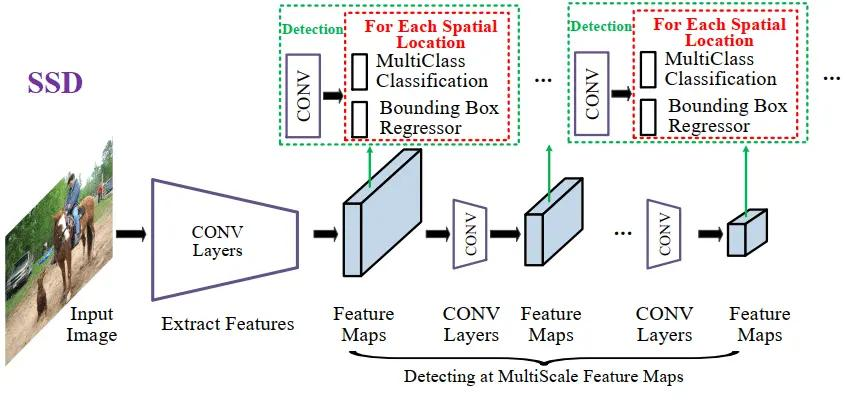!

SSD predicts object locations and classes directly from multiple feature maps of a CNN.

The interesting idea is that it uses feature maps at different resolutions.

Why?

Imagine detecting:

- A small bird.
- A medium-sized dog.
- A large bus.

A single feature-map resolution may not be equally effective for all object sizes.

SSD therefore makes predictions at multiple scales:

- Higher-resolution feature maps help detect smaller objects.
- Lower-resolution feature maps help detect larger objects.

Each location predicts candidate bounding boxes and class scores using predefined default boxes (anchors).

Remember: SSD performs object classification and bounding-box regression in one detection stage.

## 2. YOLO – You Only Look Once

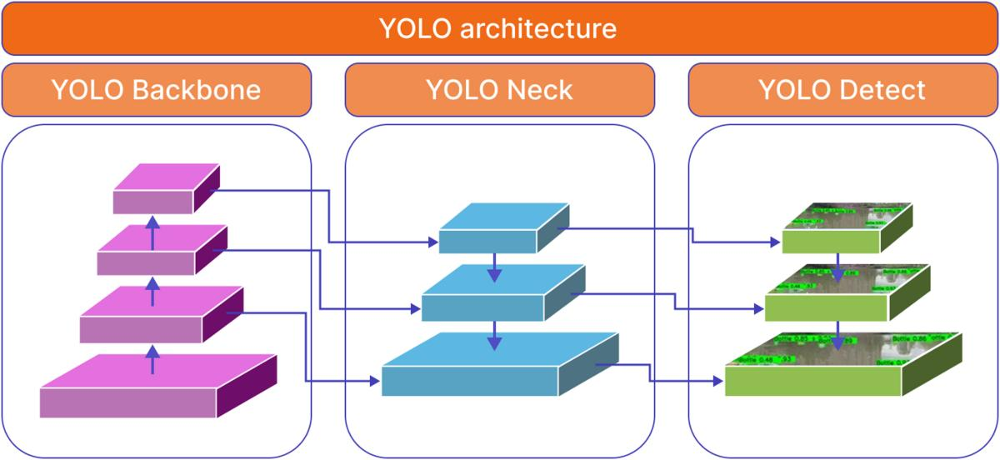!

YOLO takes the single-stage detection idea further.

Instead of separately proposing regions and classifying them, it processes the image through a neural network and predicts object locations and classes in one forward pass.

A simplified modern YOLO architecture has three major components:

Backbone

Extracts visual features from the image

Neck

Combines features from different scales

Detection Head

Predicts bounding boxes and class scores

Think of it this way:

- Backbone: What visual patterns can I identify?
- Neck: How can I combine information from different image resolutions?
- Head: Where are the objects, and what are they?

This is a simplified architecture view; exact components differ between YOLO versions.

## 3. SSD vs YOLO vs Faster R-CNN

| Feature          | Faster R-CNN                    | SSD                             | YOLO                             |
| ---------------- | ------------------------------- | ------------------------------- | -------------------------------- |
| Type             | Two-stage                       | Single-stage                    | Single-stage                     |
| Region proposals | RPN                             | No separate proposal stage      | No separate proposal stage       |
| Detection        | Proposal + classification       | Direct prediction               | Direct prediction                |
| Speed            | Generally slower                | Fast                            | Designed for real-time detection |
| Typical strength | Accurate region-based detection | Efficient multi-scale detection | Speed and practical versatility  |

These are broad architectural tendencies, not universal performance guarantees. Actual speed and accuracy depend on model size, hardware, image resolution and dataset.

## 4. Anchor-based vs Anchor-free detection

One more concept is worth understanding before we move on.

Anchor-based detection

The model starts with predefined bounding-box shapes (called anchors) at different image locations.

It learns to adjust these boxes to fit actual objects.

Anchor-free detection

The model predicts object locations and bounding-box dimensions without relying on predefined anchor-box shapes.

For example, YOLOv5 uses an anchor-based approach, whereas YOLOv8 uses an anchor-free detection head.

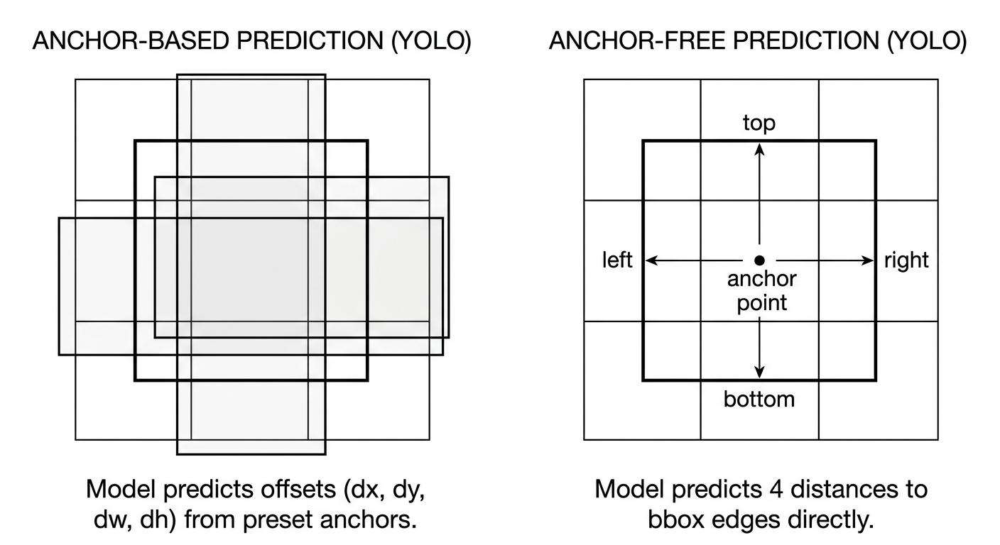!

Don't worry about their mathematical implementation for now.

## 5. When would you use them?

| Scenario                       | Possible choice                  |
| ------------------------------ | -------------------------------- |
| Real-time video analytics      | YOLO                             |
| Industrial object detection    | YOLO or SSD                      |
| Region-based detection tasks   | Faster R-CNN                     |
| Resource-constrained inference | Lightweight SSD or YOLO variants |

The best choice depends on accuracy, latency, deployment hardware and the application.

Key takeaway: Faster R-CNN uses two stages—proposing regions and detecting objects. SSD and YOLO perform detection in a single stage, making them attractive for faster inference.

### Next: Image Segmentation

We've covered image classification and object detection. Now we'll move one level deeper:

Instead of drawing a rectangle around an object, what if we want to identify the exact pixels belonging to that object?

That's image segmentation. We'll start with semantic segmentation vs instance segmentation, then U-Net and Mask R-CNN.